# Notebook 03 – Mô hình cơ sở, hồi quy đa thức bậc 1–10, Ridge và KNN
Mọi so sánh dùng **cùng 5 fold** trên tập huấn luyện (318 mẫu), phân tầng theo `origin`, gom theo `name` (`src/evaluate.py`).
Tập kiểm tra 80 mẫu **không được dùng** trong notebook này. Mỗi mô hình là một Pipeline: điền thiếu → (đa thức) → chuẩn hóa → mô hình, nên mỗi fold tự khớp lại tiền xử lý.
Chạy notebook từ thư mục `notebooks/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline

from data import NUM, CAT, TARGET, SEED, split
from preprocess import build_preprocessor
from evaluate import cv_folds, cv_score, fmt

warnings.filterwarnings("ignore", category=RuntimeWarning)   # bậc rất cao làm ma trận suy biến; kết quả vẫn được ghi lại
FIG, REP = Path("../reports/figures"), Path("../reports")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

train, test = split()
y = train[TARGET]
folds = cv_folds(train)
print("Huấn luyện:", len(train), "| kích thước phần kiểm định của từng fold:", [len(v) for _, v in folds])

Huấn luyện: 318 | kích thước phần kiểm định của từng fold: [64, 64, 64, 63, 63]


## 1. Mô hình cơ sở (baseline)
Hai mức tham chiếu: dự đoán bằng giá trị trung bình của phần huấn luyện, và hồi quy tuyến tính với đủ 7 đặc trưng (6 số + `origin` one-hot).

In [2]:
X7 = train[NUM + CAT]
ket_qua = {}
for ten, m in [("Trung bình (Dummy)", DummyRegressor()), ("Tuyến tính (7 đặc trưng)", LinearRegression())]:
    ket_qua[ten] = cv_score(make_pipeline(build_preprocessor(), m), X7, y, folds)
pd.DataFrame(ket_qua).T.round(3)

,RMSE_train,RMSE_train_std,RMSE_cv,RMSE_cv_std,MAE_train,MAE_train_std,MAE_cv,MAE_cv_std,R2_train,R2_train_std,R2_cv,R2_cv_std
Trung bình (Dummy),7.832,0.095,7.834,0.377,6.620,0.088,6.623,0.340,0.000,0.000,-0.006,0.004
Tuyến tính (7 đặc trưng),3.248,0.139,3.326,0.516,2.491,0.123,2.579,0.378,0.828,0.011,0.818,0.044


## 2. Hồi quy đa thức bậc 1–10
Đặc trưng sinh đa thức: `weight`, `horsepower`, `acceleration`, `model_year` (n = 4, đúng ví dụ ở Bảng 1). Không đưa `displacement` và `cylinders` vào nhánh đa thức vì tương quan 0,90–0,95 với `weight`/`horsepower` (VIF cao, mục 2.2.3): thêm vào chỉ làm số cột tăng nhanh mà gần như không thêm thông tin. `origin` vẫn được one-hot và đưa vào mô hình nhưng không nhân đa thức.

In [3]:
POLY = ["weight", "horsepower", "acceleration", "model_year"]
X4 = train[POLY + CAT]
rows = []
for d in range(1, 11):
    pipe = make_pipeline(build_preprocessor(POLY, CAT, degree=d), LinearRegression())
    s = cv_score(pipe, X4, y, folds)
    n_feat = pipe.fit(X4, y)[0].transform(X4.iloc[:5]).shape[1]
    rows.append({"Bậc": d, "Số đặc trưng": n_feat, **s})
poly = pd.DataFrame(rows).set_index("Bậc")
poly.to_csv(REP / "bang_da_thuc_bac_1_10.csv")
poly[["Số đặc trưng", "RMSE_train", "RMSE_cv", "RMSE_cv_std", "R2_cv"]].round(3)

,Số đặc trưng,RMSE_train,RMSE_cv,RMSE_cv_std,R2_cv
Bậc,,,,,
1,7,3.308,3.367,0.539,0.813
2,17,2.699,2.871,0.399,0.864
3,37,2.398,3.623,1.860,0.743
4,72,2.200,3.519,0.775,0.783
5,128,2.056,12.332,12.800,-3.753
6,212,1.977,9.168,4.459,-0.611
7,332,1.938,18.461,21.894,-11.302
8,497,1.861,27.527,28.758,-23.307
9,717,1.801,24.875,10.836,-10.970


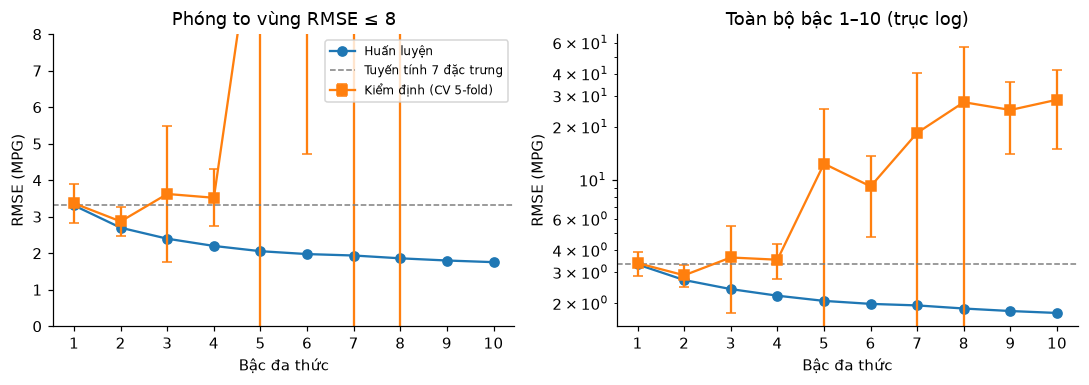

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, ylog in zip(ax, [False, True]):
    a.plot(poly.index, poly["RMSE_train"], "o-", label="Huấn luyện")
    a.errorbar(poly.index, poly["RMSE_cv"], yerr=poly["RMSE_cv_std"], fmt="s-", capsize=3, label="Kiểm định (CV 5-fold)")
    a.axhline(ket_qua["Tuyến tính (7 đặc trưng)"]["RMSE_cv"], ls="--", c="gray", lw=1, label="Tuyến tính 7 đặc trưng")
    a.set_xlabel("Bậc đa thức"); a.set_ylabel("RMSE (MPG)"); a.set_xticks(range(1, 11))
    if ylog: a.set_yscale("log"); a.set_title("Toàn bộ bậc 1–10 (trục log)")
    else: a.set_ylim(0, 8); a.set_title("Phóng to vùng RMSE ≤ 8")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_1_loi_theo_bac.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Lỗi huấn luyện giảm đơn điệu từ 3,31 (bậc 1) xuống 1,76 (bậc 10) vì số đặc trưng tăng từ 7 lên 1003. Lỗi kiểm định có dạng chữ U như mục 1.2.1: thấp nhất ở **bậc 2** (RMSE CV 2,87 ± 0,40, R² 0,86), rồi tăng lại: bậc 3–4 khoảng 3,5–3,6 với độ lệch chuẩn lớn (1,86 ở bậc 3), từ bậc 5 trở đi bùng nổ (12,33 ở bậc 5, 28,43 ở bậc 10, R² âm).
- **Underfitting ở bậc 1:** lỗi huấn luyện (3,31) và kiểm định (3,37) cùng cao và gần nhau (chênh 0,06).
- **Overfitting từ bậc 3:** khoảng cách huấn luyện – kiểm định tăng từ 1,22 (bậc 3) lên 26,7 (bậc 10); độ lệch chuẩn giữa các fold cũng tăng, tức variance tăng.
- Nguyên nhân: bậc 5 đã có 128 đặc trưng cho khoảng 254 mẫu huấn luyện mỗi fold, bậc 8–10 thì số đặc trưng (497–1003) vượt số mẫu; nghiệm bình phương tối thiểu khớp cả nhiễu và ngoại suy rất kém ở các mẫu kiểm định nằm ở rìa miền dữ liệu.

## 3. Ridge: quét α trên lưới logarit ở bậc 2, 6 và 10

In [5]:
alphas = np.logspace(-4, 4, 17)
rows = []
for d in [2, 6, 10]:
    for a_ in alphas:
        s = cv_score(make_pipeline(build_preprocessor(POLY, CAT, degree=d), Ridge(alpha=a_)), X4, y, folds)
        rows.append({"Bậc": d, "alpha": a_, **s})
ridge = pd.DataFrame(rows)
ridge.to_csv(REP / "bang_ridge.csv", index=False)
tot_nhat = ridge.loc[ridge.groupby("Bậc")["RMSE_cv"].idxmin()]
tot_nhat[["Bậc", "alpha", "RMSE_train", "RMSE_cv", "RMSE_cv_std", "R2_cv"]].round(3)

,Bậc,alpha,RMSE_train,RMSE_cv,RMSE_cv_std,R2_cv
7,2,0.316,2.741,2.839,0.427,0.867
27,6,10.000,2.674,2.833,0.392,0.868
45,10,31.623,2.622,2.838,0.351,0.868


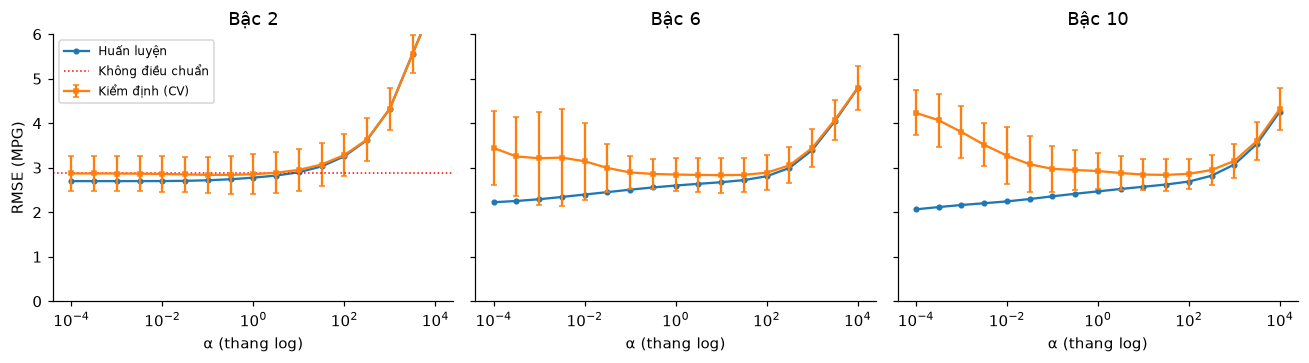

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, d in zip(ax, [2, 6, 10]):
    r = ridge[ridge["Bậc"] == d]
    a.semilogx(r["alpha"], r["RMSE_train"], "o-", ms=3, label="Huấn luyện")
    a.errorbar(r["alpha"], r["RMSE_cv"], yerr=r["RMSE_cv_std"], fmt="s-", ms=3, capsize=2, label="Kiểm định (CV)")
    a.axhline(poly.loc[d, "RMSE_cv"] if poly.loc[d, "RMSE_cv"] < 8 else np.nan, ls=":", c="red", lw=1, label="Không điều chuẩn")
    a.set_title(f"Bậc {d}"); a.set_xlabel("α (thang log)"); a.set_ylim(0, 6)
ax[0].set_ylabel("RMSE (MPG)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_2_ridge_theo_alpha.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Ridge kiểm soát được overfitting ở bậc cao. Với α tốt nhất, RMSE CV ở bậc 2, 6, 10 là 2,84 (α = 0,32), 2,83 (α = 10) và 2,84 (α = 31,6), so với 2,87, 9,17 và 28,43 khi không điều chuẩn (bậc 10 giảm 10 lần). Hình cho thấy ba vùng:
- α rất nhỏ (10⁻⁴): gần như không điều chuẩn, khoảng cách huấn luyện – kiểm định lớn (bậc 10: 2,06 so với 4,23).
- α vừa (1–100): cân bằng tốt nhất, RMSE CV 2,83–2,93.
- α lớn (≥ 10³): phạt quá mạnh, hệ số bị ép về 0, lỗi huấn luyện và kiểm định cùng tăng (bậc 2 lên 4,33 rồi 6,78 ở α = 10⁴), tức underfitting.

Bậc càng cao thì α tối ưu càng lớn vì càng nhiều đặc trưng tương quan cần thu hẹp; ở bậc 2, α gần như không ảnh hưởng cho tới khoảng 1. Ba mô hình tốt nhất chênh nhau dưới 0,01 trong khi độ lệch chuẩn qua fold là 0,35–0,43, nên **không thể nói bậc nào tốt hơn**; theo nguyên tắc chọn mô hình đơn giản nhất, bậc 2 là lựa chọn hợp lý.

## 4. KNN: quét số láng giềng k
KNN dùng đủ 7 đặc trưng đã chuẩn hóa (khoảng cách Euclid nhạy với thang đo, mục 1.3.2).

In [7]:
rows = []
for k in list(range(1, 21)) + [25, 30, 40, 50]:
    s = cv_score(make_pipeline(build_preprocessor(), KNeighborsRegressor(n_neighbors=k)), X7, y, folds)
    rows.append({"k": k, **s})
knn = pd.DataFrame(rows).set_index("k")
knn.to_csv(REP / "bang_knn.csv")
k_best = knn["RMSE_cv"].idxmin()
print("k tốt nhất theo CV:", k_best)
knn.loc[[1, 3, 5, k_best, 10, 20, 50], ["RMSE_train", "RMSE_cv", "RMSE_cv_std", "R2_cv"]].round(3)

k tốt nhất theo CV: 3


,RMSE_train,RMSE_cv,RMSE_cv_std,R2_cv
k,,,,
1,0.000,3.812,0.560,0.759
3,2.219,3.114,0.457,0.840
5,2.490,3.139,0.496,0.837
3,2.219,3.114,0.457,0.840
10,2.911,3.204,0.573,0.829
20,3.169,3.310,0.574,0.819
50,3.425,3.466,0.387,0.803


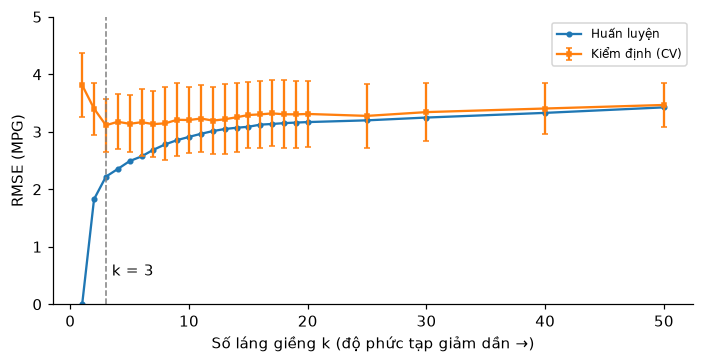

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(knn.index, knn["RMSE_train"], "o-", ms=3, label="Huấn luyện")
ax.errorbar(knn.index, knn["RMSE_cv"], yerr=knn["RMSE_cv_std"], fmt="s-", ms=3, capsize=2, label="Kiểm định (CV)")
ax.axvline(k_best, ls="--", c="gray", lw=1); ax.text(k_best + 0.5, 0.5, f"k = {k_best}")
ax.set_xlabel("Số láng giềng k (độ phức tạp giảm dần →)"); ax.set_ylabel("RMSE (MPG)"); ax.set_ylim(0, 5); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_3_knn_theo_k.png", bbox_inches="tight"); plt.show()

**Nhận xét.** k = 1 khớp hoàn hảo tập huấn luyện (RMSE 0) nhưng RMSE CV 3,81: overfitting (variance cao). k lớn làm đường dự đoán trơn dần: k = 50 có RMSE huấn luyện 3,42 và CV 3,47, gần nhau và cùng cao, tức underfitting. Tốt nhất là **k = 3** (RMSE CV 3,11 ± 0,46), khá hơn hồi quy tuyến tính (3,33) nhưng kém đa thức bậc 2 và Ridge (2,83–2,87). Lý do: với 318 mẫu trong 7 chiều, KNN coi mọi đặc trưng nặng như nhau khi tính khoảng cách, kể cả `acceleration` vốn ít giá trị dự đoán, và không ngoại suy được ở vùng rìa (xe rất nhẹ hoặc rất nặng) vì chỉ lấy trung bình các xe lân cận.

## 5. Bảng so sánh các mô hình với baseline (cùng 5 fold, cùng chỉ số)

In [9]:
d_best = int(poly["RMSE_cv"].idxmin())
r_best = ridge.loc[ridge["RMSE_cv"].idxmin()]
mo_hinh = {
    "Trung bình (Dummy)": (make_pipeline(build_preprocessor(), DummyRegressor()), X7),
    "Tuyến tính (7 đặc trưng)": (make_pipeline(build_preprocessor(), LinearRegression()), X7),
    "Tuyến tính (4 đặc trưng, bậc 1)": (make_pipeline(build_preprocessor(POLY, CAT, 1), LinearRegression()), X4),
    f"Đa thức bậc {d_best} (tốt nhất)": (make_pipeline(build_preprocessor(POLY, CAT, d_best), LinearRegression()), X4),
    "Đa thức bậc 10": (make_pipeline(build_preprocessor(POLY, CAT, 10), LinearRegression()), X4),
    f"Ridge bậc {int(r_best['Bậc'])}, α = {r_best['alpha']:g}": (make_pipeline(build_preprocessor(POLY, CAT, int(r_best["Bậc"])), Ridge(alpha=r_best["alpha"])), X4),
    f"KNN k = {k_best}": (make_pipeline(build_preprocessor(), KNeighborsRegressor(n_neighbors=k_best)), X7),
}
so_sanh = pd.DataFrame({ten: cv_score(m, X, y, folds) for ten, (m, X) in mo_hinh.items()}).T
so_sanh.to_csv(REP / "bang_so_sanh_mo_hinh.csv")
bang = pd.DataFrame({
    "RMSE huấn luyện": [fmt(r.RMSE_train, r.RMSE_train_std) for r in so_sanh.itertuples()],
    "RMSE CV": [fmt(r.RMSE_cv, r.RMSE_cv_std) for r in so_sanh.itertuples()],
    "MAE CV": [fmt(r.MAE_cv, r.MAE_cv_std) for r in so_sanh.itertuples()],
    "R² CV": [fmt(r.R2_cv, r.R2_cv_std) for r in so_sanh.itertuples()],
}, index=so_sanh.index)
bang

,RMSE huấn luyện,RMSE CV,MAE CV,R² CV
Trung bình (Dummy),"7,83 ± 0,09","7,83 ± 0,38","6,62 ± 0,34","-0,01 ± 0,00"
Tuyến tính (7 đặc trưng),"3,25 ± 0,14","3,33 ± 0,52","2,58 ± 0,38","0,82 ± 0,04"
"Tuyến tính (4 đặc trưng, bậc 1)","3,31 ± 0,14","3,37 ± 0,54","2,56 ± 0,36","0,81 ± 0,05"
Đa thức bậc 2 (tốt nhất),"2,70 ± 0,11","2,87 ± 0,40","2,11 ± 0,29","0,86 ± 0,03"
Đa thức bậc 10,"1,76 ± 0,10","28,43 ± 13,39","9,71 ± 3,66","-15,07 ± 12,34"
"Ridge bậc 6, α = 10","2,67 ± 0,10","2,83 ± 0,39","2,08 ± 0,29","0,87 ± 0,03"
KNN k = 3,"2,22 ± 0,07","3,11 ± 0,46","2,20 ± 0,36","0,84 ± 0,04"


**Nhận xét.** Ridge bậc 6 (α = 10) tốt nhất: RMSE CV 2,83 ± 0,39 so với 3,33 ± 0,52 của baseline tuyến tính (giảm 15%), R² từ 0,82 lên 0,87, MAE từ 2,58 xuống 2,08; độ lệch chuẩn qua fold cũng nhỏ hơn nên ổn định hơn. Đa thức bậc 2 không điều chuẩn gần bằng (2,87). Tuyến tính 4 đặc trưng (3,37) gần bằng tuyến tính 7 đặc trưng (3,33), xác nhận bỏ `displacement`, `cylinders` khỏi nhánh đa thức gần như không mất thông tin. Mọi mô hình đều vượt xa mô hình dự đoán trung bình (RMSE 7,83, R² ≈ 0). Đa thức bậc 10 không điều chuẩn tệ hơn cả mô hình trung bình (RMSE 28,43), là ví dụ rõ nhất của overfitting.

## 6. Biểu đồ phần dư và dự đoán – thực tế (dự đoán ngoài fold)
Mỗi điểm được dự đoán bởi mô hình **không** thấy điểm đó lúc huấn luyện (`cross_val_predict` với cùng 5 fold).

Tuyến tính (7 đặc trưng) | phần dư TB theo khoảng dự đoán: {Interval(0, 15, closed='right'): 2.15, Interval(15, 20, closed='right'): -0.9, Interval(20, 25, closed='right'): -1.8, Interval(25, 30, closed='right'): -0.44, Interval(30, 50, closed='right'): 1.79}
Ridge bậc 6, α = 10 | phần dư TB theo khoảng dự đoán: {Interval(0, 15, closed='right'): 0.16, Interval(15, 20, closed='right'): 0.05, Interval(20, 25, closed='right'): -0.39, Interval(25, 30, closed='right'): -0.04, Interval(30, 50, closed='right'): 0.25}


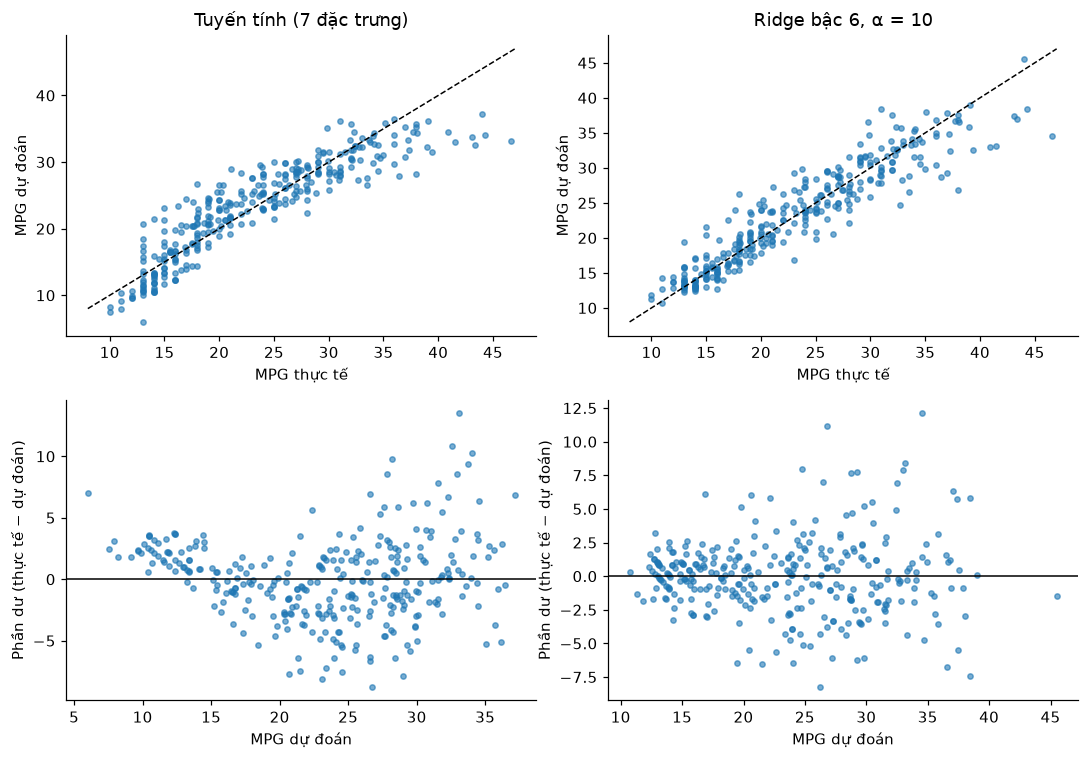

In [10]:
ten_ridge = [t for t in mo_hinh if t.startswith("Ridge")][0]
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for j, ten in enumerate(["Tuyến tính (7 đặc trưng)", ten_ridge]):
    m, X = mo_hinh[ten]
    p = cross_val_predict(m, X, y, cv=folds)
    ax[0, j].scatter(y, p, s=12, alpha=.6); ax[0, j].plot([8, 47], [8, 47], "k--", lw=1)
    ax[0, j].set_xlabel("MPG thực tế"); ax[0, j].set_ylabel("MPG dự đoán"); ax[0, j].set_title(ten)
    ax[1, j].scatter(p, y - p, s=12, alpha=.6); ax[1, j].axhline(0, c="k", lw=1)
    ax[1, j].set_xlabel("MPG dự đoán"); ax[1, j].set_ylabel("Phần dư (thực tế − dự đoán)")
    print(ten, "| phần dư TB theo khoảng dự đoán:",
          (y - p).groupby(pd.cut(p, [0, 15, 20, 25, 30, 50])).mean().round(2).to_dict())
plt.tight_layout(); plt.savefig(FIG / "hinh_3_4_phan_du.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Phần dư của hồi quy tuyến tính có dạng chữ U: dương ở hai đầu (trung bình +2,15 khi dự đoán dưới 15 MPG và +1,79 khi trên 30 MPG), âm ở giữa (−1,80 ở khoảng 20–25). Mô hình tuyến tính bỏ sót độ cong của quan hệ, đúng như dự đoán từ biểu đồ phân tán ở Hình 2.5, và đây là dấu hiệu underfitting. Với Ridge bậc 6, phần dư trung bình theo từng khoảng chỉ còn trong ±0,4 nên độ cong đã được nắm bắt. Tuy vậy độ phân tán của phần dư vẫn tăng theo MPG (rộng hơn hẳn ở vùng trên 25 MPG), và các xe tiết kiệm nhất (trên 40 MPG) vẫn bị dự đoán thấp. Đây là gợi ý cho bước cải tiến ở notebook 05 (học trên log(MPG), thêm thông tin còn thiếu).